In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bandit import BanditGames
from multi_level_rl import ParametricPopulation
import torch
from utils import plot_3d_experiment_3d_lines

import matplotlib.gridspec as gridspec

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

plt.rcParams["text.latex.preamble"] = r"\usepackage{lmodern} \usepackage{amsmath}"
# Options
params = {
    "text.usetex": True,
    "font.size": 15,
    "font.family": "lmodern",
    #   'text.latex.unicode': True,
}
plt.rcParams.update(params)

In [ ]:
# bare-bones check: follow a few agents under naive PG
n_agents = 100
steps = 1000
pop = ParametricPopulation(size=n_agents, spread=1)

history = torch.zeros(steps, n_agents, pop.arms)
for t in range(steps):
    history[t] = torch.softmax(pop.params, dim=-1)
    pop.update_policy_pg(alpha=1, lola_alpha=0.0, lola=False)

# fig, axes = plt.subplots(1, pop.arms, figsize=(12, 3.5), sharey=True)
# for a, name in enumerate(["Rock", "Paper", "Scissors"]):
#     axes[a].plot(history[:, :, a])  # one line per agent
#     axes[a].axhline(1 / 3, color="k", ls="--", lw=0.8)
#     axes[a].set_title(name)
#     axes[a].set_xlabel("Step")
# axes[0].set_ylabel("Probability")

In [ ]:
# 3D view with the plotting function from rl_societies.ipynb
# (it expects logits and applies softmax, so pass log-probabilities)
plot_3d_experiment_3d_lines(
    "R", "P", "S", torch.log(history), title="RPS - PG", azim=-50, dpi=100
)

In [ ]:
n_agents = 10
steps = 20
pop = ParametricPopulation(size=n_agents, spread=3)

history_lola = torch.zeros(steps, n_agents, pop.arms)
for t in range(steps):
    history_lola[t] = torch.softmax(pop.params, dim=-1)
    pop.update_policy_pg(alpha=1, lola_alpha=1, lola=True)

In [ ]:
# 3D view with the plotting function from rl_societies.ipynb
# (it expects logits and applies softmax, so pass log-probabilities)
plot_3d_experiment_3d_lines(
    "R", "P", "S", torch.log(history_lola), title="RPS - LOLA", azim=-50, dpi=100
)

torch.Size([500, 1000, 3])


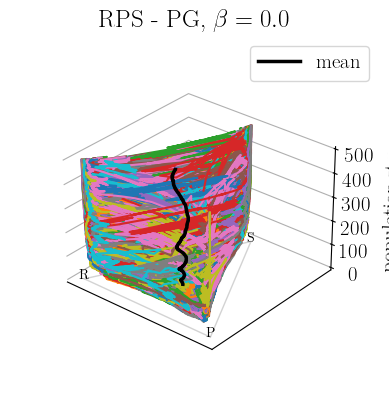

torch.Size([500, 1000, 3])


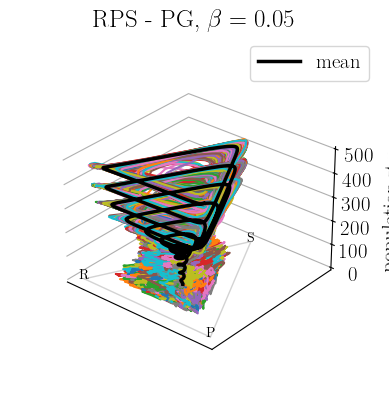

In [4]:
# PG with and without imitation: triangle plots
n_agents = 1000
steps = 500
alpha = 1.0
betas = [0.0, 0.05]  # beta = 0 is plain PG

histories = {}
for beta in betas:
    torch.manual_seed(0)  # same pairings and imitation draws for both runs
    pop = ParametricPopulation(
        size=n_agents, spread=1
    )  # same initial policies (init_logits seed=0)
    histories[beta] = torch.zeros(steps, n_agents, pop.arms)
    for t in range(steps):
        histories[beta][t] = torch.softmax(pop.params, dim=-1)
        pop.update_param_hybrid(lola=False, lola_alpha=0.0, alpha=alpha, beta=beta)

for beta, history in histories.items():
    plot_3d_experiment_3d_lines(
        "R",
        "P",
        "S",
        torch.log(history),
        title=rf"RPS - PG, $\beta = {beta}$",
        azim=-50,
        dpi=100,
    )

In [8]:
# RPS: effect of imitation strength (beta) for PG and LOLA learners
betas = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 0.7, 0.9]  # no imitation, small, large
n_agents = 1000
n_show = 30  # agents drawn as thin lines; the mean uses all agents
settings = {
    "PG": dict(lola=False, lola_alpha=0.0, steps=500),
    "LOLA": dict(lola=True, lola_alpha=1.0, steps=150),
}

results = {}
for learner, cfg in settings.items():
    for beta in betas:
        torch.manual_seed(0)  # same start, pairings and draws for every beta
        pop = ParametricPopulation(size=n_agents, spread=1)
        show = torch.randperm(n_agents)[:n_show]
        mean_hist = torch.zeros(cfg["steps"], pop.arms)
        agent_hist = torch.zeros(cfg["steps"], n_show, pop.arms)
        agent_dist = torch.zeros(cfg["steps"])
        for t in range(cfg["steps"]):
            pi = torch.softmax(pop.params, dim=-1)
            mean_hist[t] = pi.mean(0)
            agent_hist[t] = pi[show]
            agent_dist[t] = (pi - 1 / 3).norm(dim=-1).mean()
            pop.update_param_hybrid(
                lola=cfg["lola"], lola_alpha=cfg["lola_alpha"], alpha=1.0, beta=beta
            )
        results[learner, beta] = dict(
            mean=mean_hist, agents=agent_hist, agent_dist=agent_dist
        )

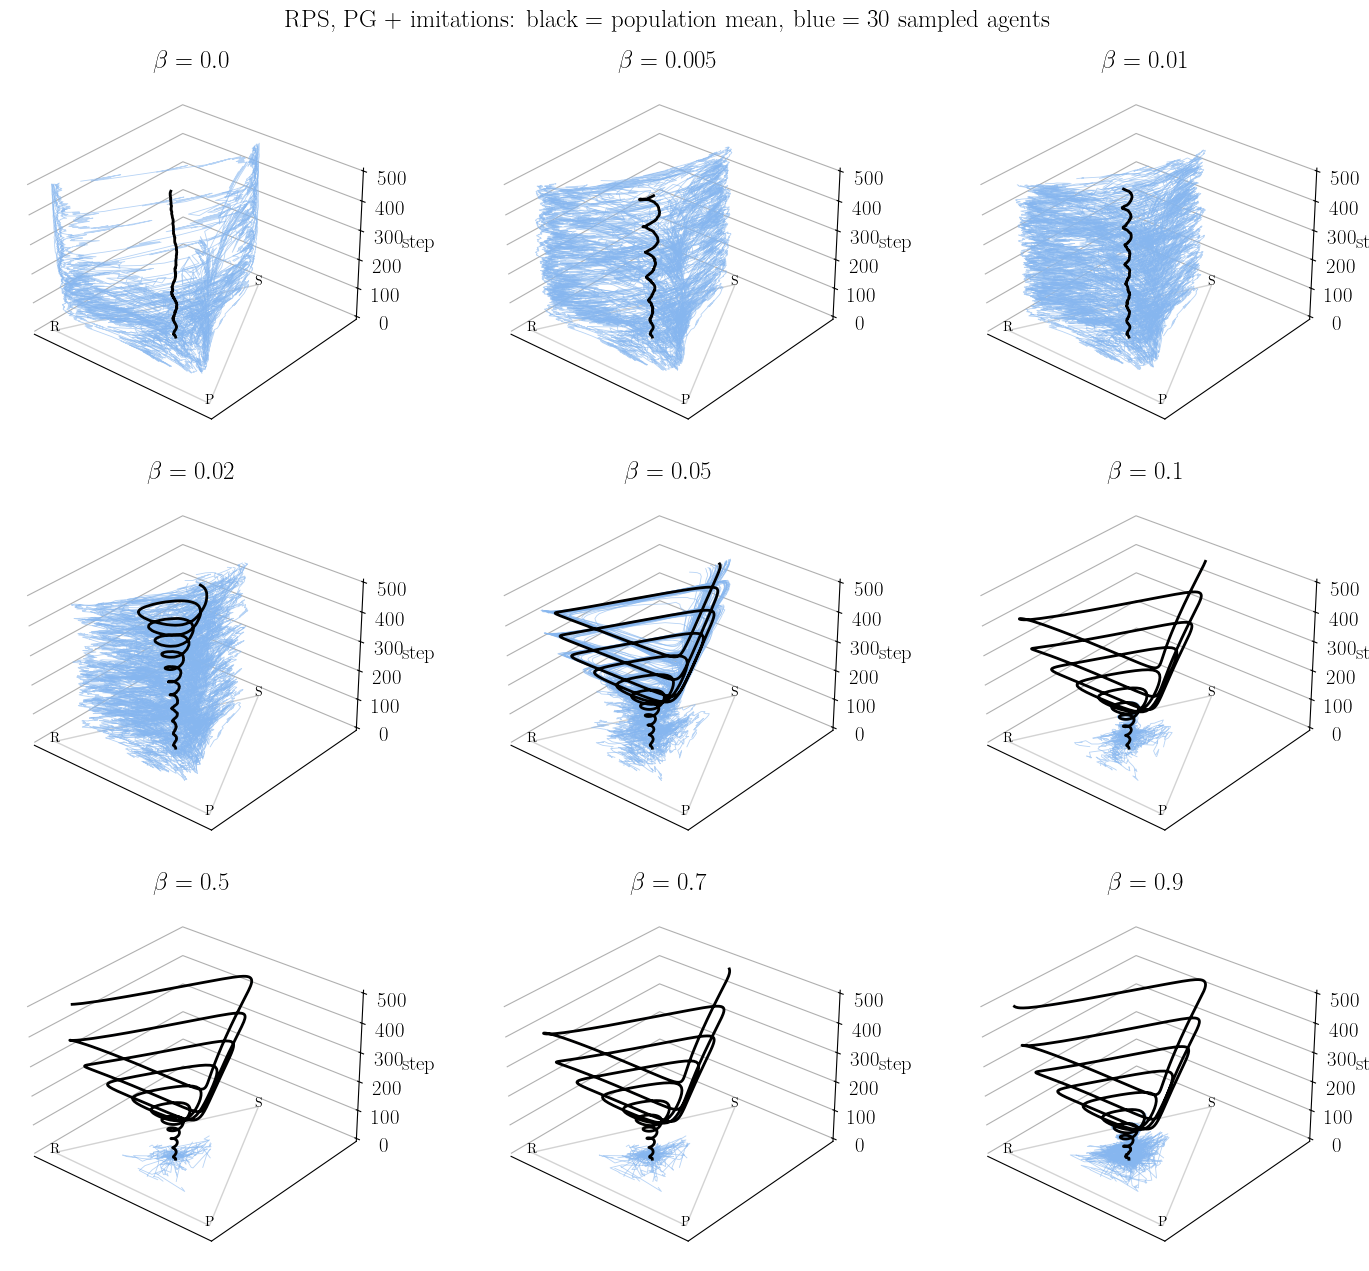

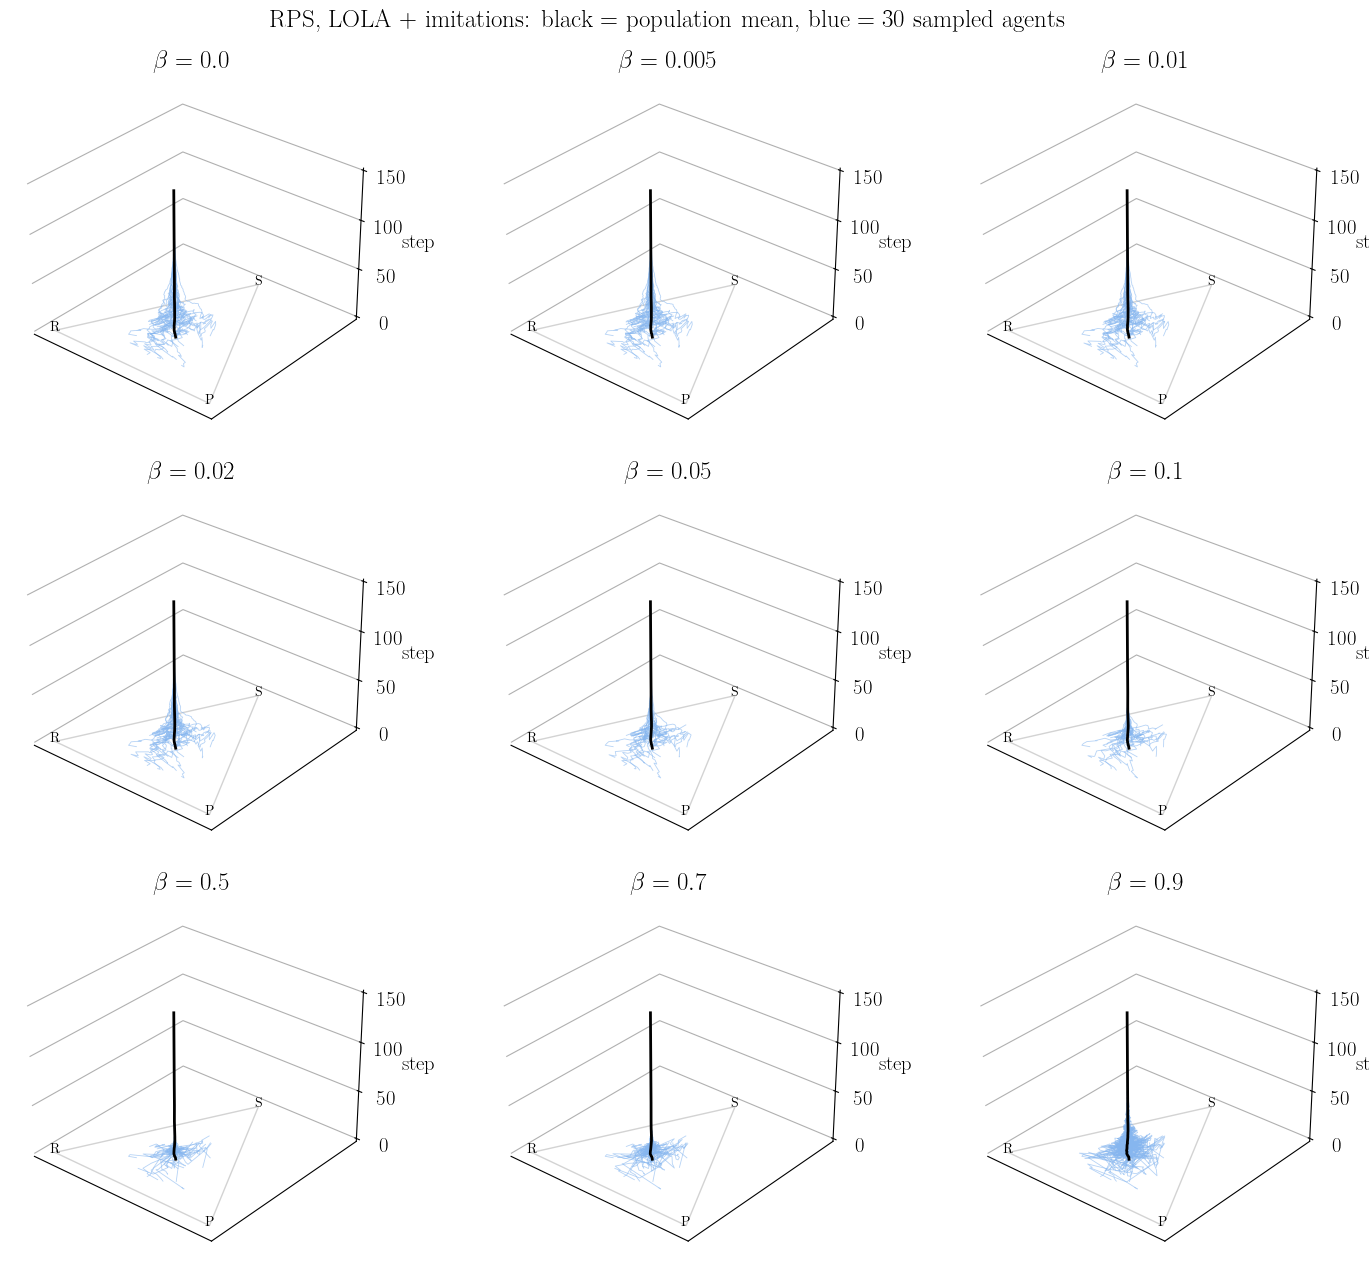

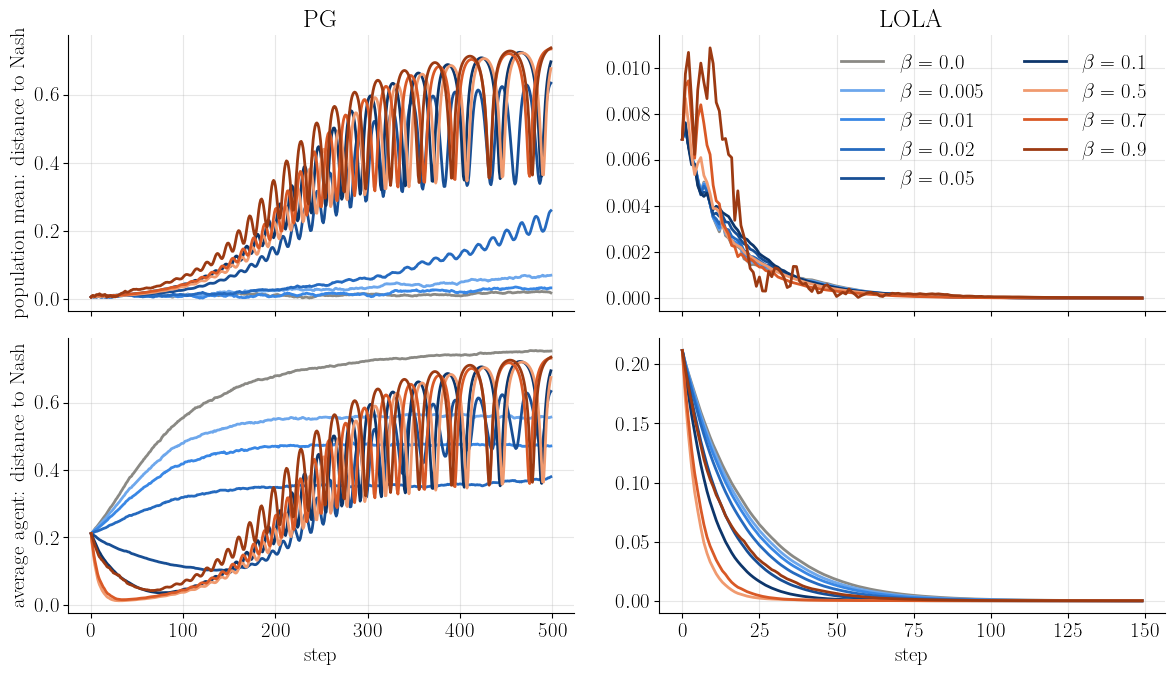

In [10]:
TRI = torch.tensor([[0.0, 0.0], [1.0, 0.0], [0.5, 3**0.5 / 2]])  # R, P, S corners
# beta = 0 grey; small betas a blue ramp (light -> dark); large betas an orange ramp
BETA_COLORS = [
    "#8a8984",
    "#6da7ec",
    "#3987e5",
    "#256abf",
    "#184f95",
    "#0d366b",
    "#f09a6f",
    "#d95926",
    "#9c3a12",
]


def triangle_panel(ax, res, title):
    steps = len(res["mean"])
    t = torch.arange(steps)
    edge = torch.cat([TRI, TRI[:1]])
    ax.plot(edge[:, 0], edge[:, 1], 0, c="lightgrey", lw=1)
    for name, (x, y) in zip("RPS", TRI):
        ax.text(x, y, 0, name, ha="center", fontsize=10)
    agents_2d = res["agents"] @ TRI
    for i in range(agents_2d.shape[1]):
        ax.plot(
            agents_2d[:, i, 0], agents_2d[:, i, 1], t, c="#86b6ef", lw=0.6, alpha=0.6
        )
    mean_2d = res["mean"] @ TRI
    ax.plot(mean_2d[:, 0], mean_2d[:, 1], t, c="k", lw=2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zlabel("step")
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor("w")
    ax.view_init(azim=-50)
    ax.set_title(title)


for learner in settings:
    fig = plt.figure(figsize=(15, 13))
    for k, beta in enumerate(betas):
        ax = fig.add_subplot(3, 3, k + 1, projection="3d")
        triangle_panel(ax, results[learner, beta], rf"$\beta = {beta}$")
    fig.suptitle(
        rf"RPS, {learner} + imitations: black = population mean, blue = {n_show} sampled agents"
    )
    plt.tight_layout()
    plt.show()

# summary: distance to Nash over time for every beta
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for col, learner in enumerate(settings):
    for beta, color in zip(betas, BETA_COLORS):
        res = results[learner, beta]
        axes[0, col].plot(
            (res["mean"] - 1 / 3).norm(dim=-1),
            c=color,
            lw=2,
            label=rf"$\beta = {beta}$",
        )
        axes[1, col].plot(res["agent_dist"], c=color, lw=2)
    axes[0, col].set_title(learner)
    axes[1, col].set_xlabel("step")
axes[0, 0].set_ylabel("population mean: distance to Nash")
axes[1, 0].set_ylabel("average agent: distance to Nash")
axes[0, 1].legend(frameon=False, ncol=2)
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [2]:
# Two-action games (Hawk-Dove, Stag Hunt): sweep over beta for PG and LOLA, and plots
# each policy is one number, p(first action), so time goes on the x-axis instead of a triangle
BETAS_2A = [
    0.0,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.5,
    0.7,
    0.9,
]  # no imitation, small, large
# beta = 0 grey; small betas a blue ramp (light -> dark); large betas an orange ramp
BETA_COLORS_2A = [
    "#8a8984",
    "#6da7ec",
    "#3987e5",
    "#256abf",
    "#184f95",
    "#0d366b",
    "#f09a6f",
    "#d95926",
    "#9c3a12",
]


def run_two_action_sweep(game, steps, n_agents=1000, n_show=30):
    results = {}
    for learner, lola in (("PG", False), ("LOLA", True)):
        for beta in BETAS_2A:
            torch.manual_seed(0)  # same start, pairings and draws for every beta
            pop = ParametricPopulation(size=n_agents, game=game, spread=1)
            show = torch.randperm(n_agents)[:n_show]
            p_hist = torch.zeros(steps, n_agents)
            for t in range(steps):
                p_hist[t] = torch.softmax(pop.params, dim=-1)[:, 0]
                pop.update_param_hybrid(
                    lola=lola, lola_alpha=1.0 if lola else 0.0, alpha=1.0, beta=beta
                )
            results[learner, beta] = dict(
                mean=p_hist.mean(1), std=p_hist.std(1), agents=p_hist[:, show]
            )
    return results


def plot_two_action_sweep(results, game_name, action, reference, reference_label):
    for learner in ("PG", "LOLA"):
        fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)
        for ax, beta in zip(axes.flat, BETAS_2A):
            res = results[learner, beta]
            ax.plot(res["agents"], c="#86b6ef", lw=0.6, alpha=0.6)
            ax.plot(res["mean"], c="k", lw=2)
            ax.axhline(reference, c="#8a8984", ls="--", lw=1)
            ax.set_title(rf"$\beta = {beta}$")
            ax.set_ylim(-0.02, 1.02)
            ax.spines[["top", "right"]].set_visible(False)
        for ax in axes[-1]:
            ax.set_xlabel("step")
        for ax in axes[:, 0]:
            ax.set_ylabel(f"p({action})")
        fig.suptitle(
            rf"{game_name}, {learner} ($\alpha = 1$): black = population mean, "
            rf"blue = sampled agents, dashed = {reference_label}"
        )
        plt.tight_layout()
        plt.show()

    # summary: mean and spread across agents over time for every beta
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for col, learner in enumerate(("PG", "LOLA")):
        for beta, color in zip(BETAS_2A, BETA_COLORS_2A):
            res = results[learner, beta]
            axes[0, col].plot(res["mean"], c=color, lw=2, label=rf"$\beta = {beta}$")
            axes[1, col].plot(res["std"], c=color, lw=2)
        axes[0, col].axhline(reference, c="#8a8984", ls="--", lw=1)
        axes[0, col].set_title(f"{game_name}, {learner}")
        axes[1, col].set_xlabel("step")
    axes[0, 0].set_ylabel(f"population mean p({action})")
    axes[1, 0].set_ylabel(f"spread across agents (std)")
    axes[0, 1].legend(
        frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1)
    )  # outside, so no lines are hidden
    for ax in axes.flat:
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

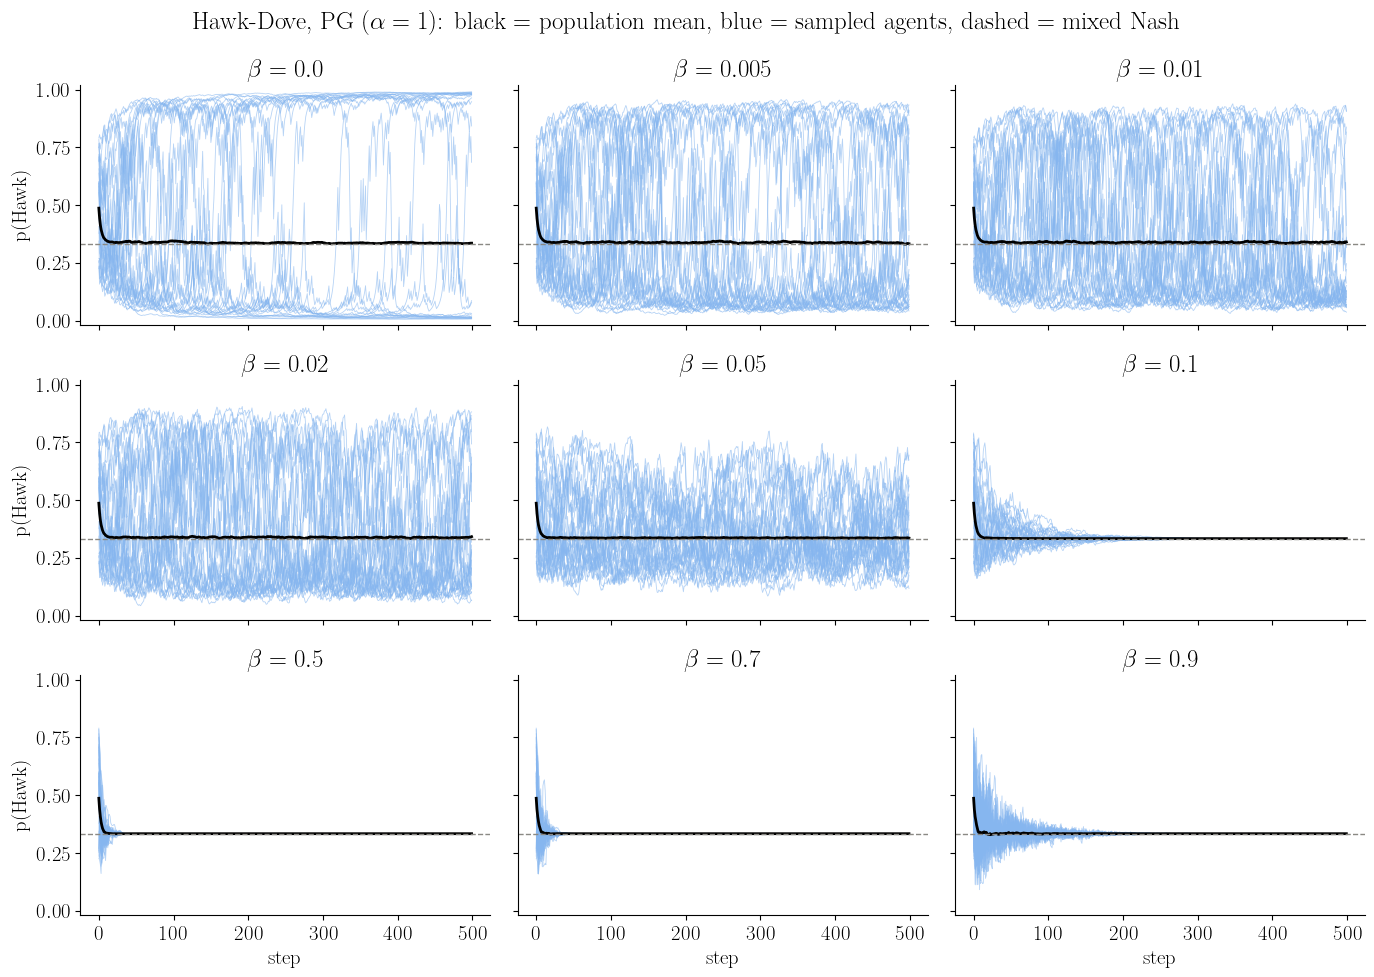

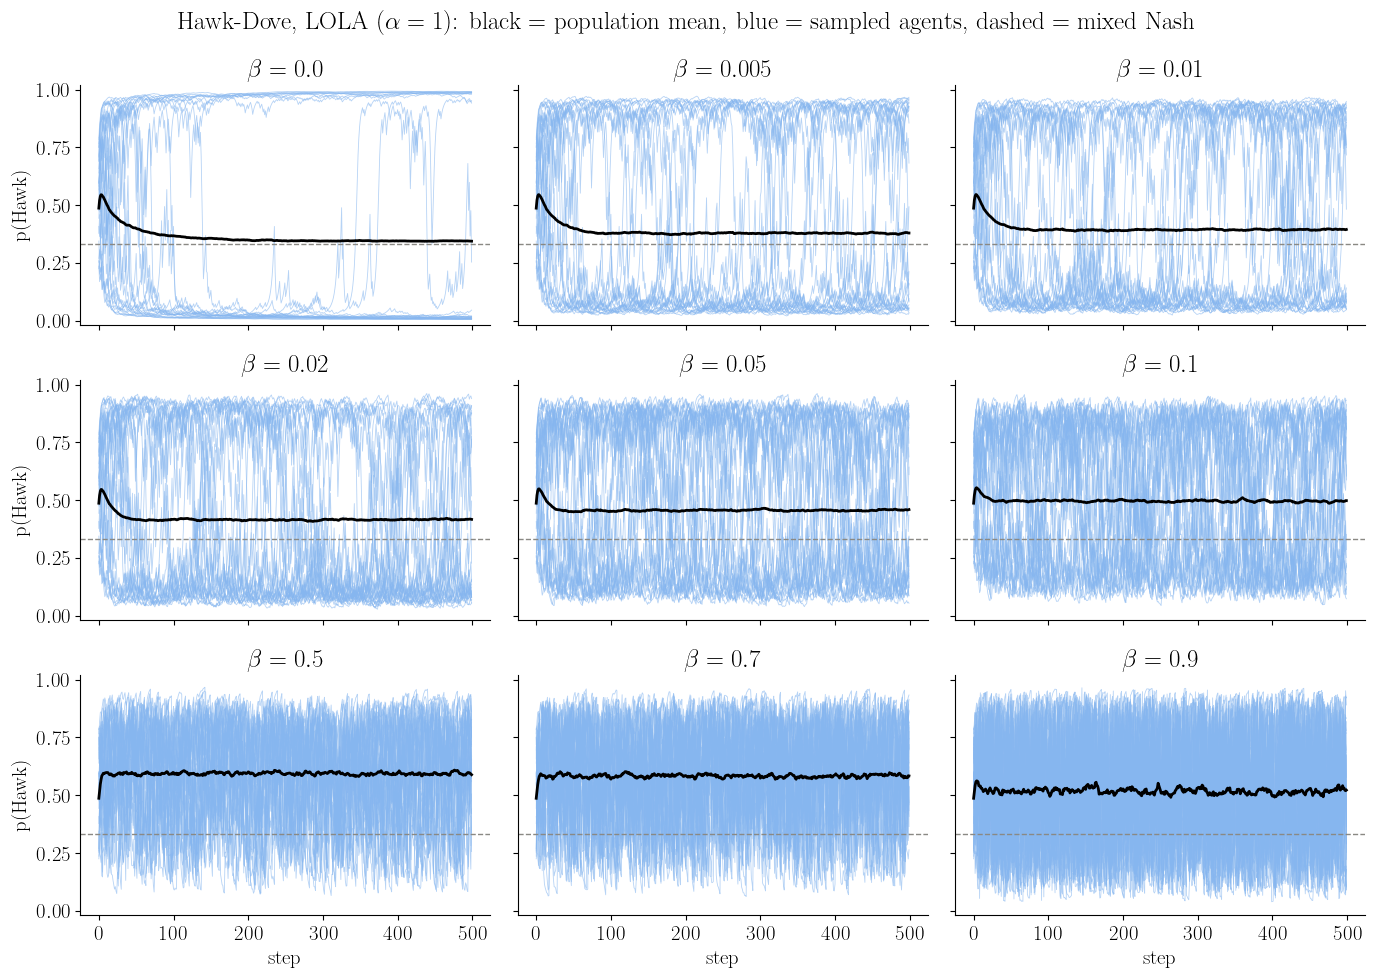

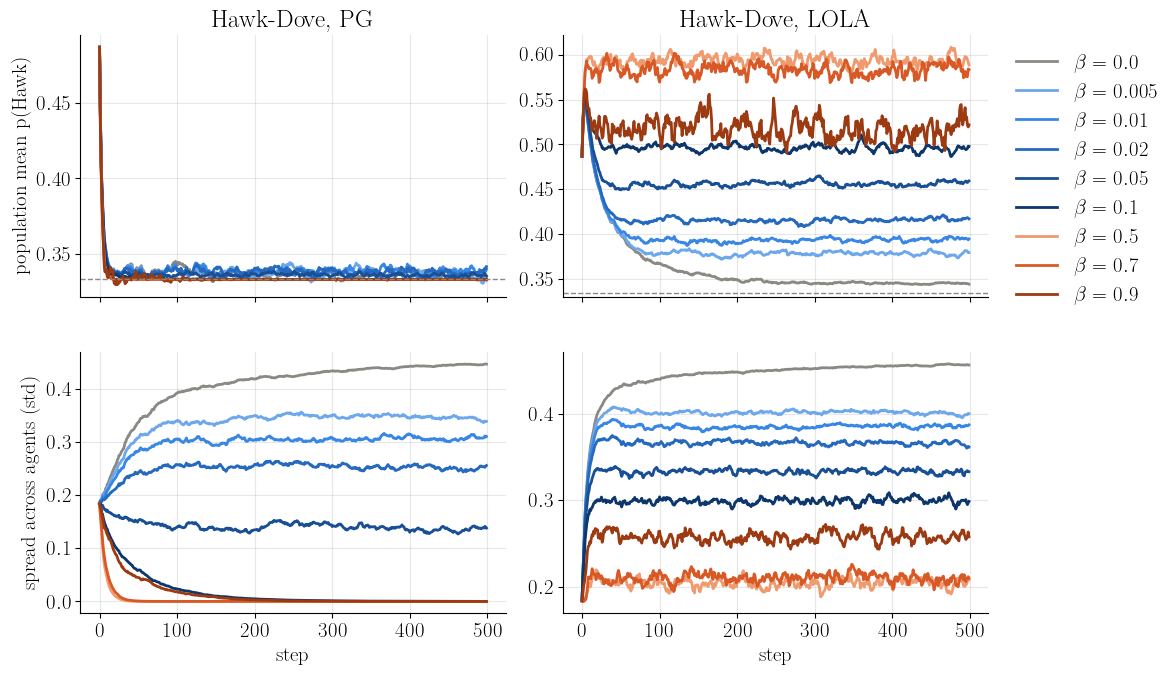

In [3]:
# Hawk-Dove (paper's "hd-2"): mixed Nash at p(Hawk) = 1/3
hd_results = run_two_action_sweep("hd", steps=500)
plot_two_action_sweep(hd_results, "Hawk-Dove", "Hawk", 1 / 3, "mixed Nash")

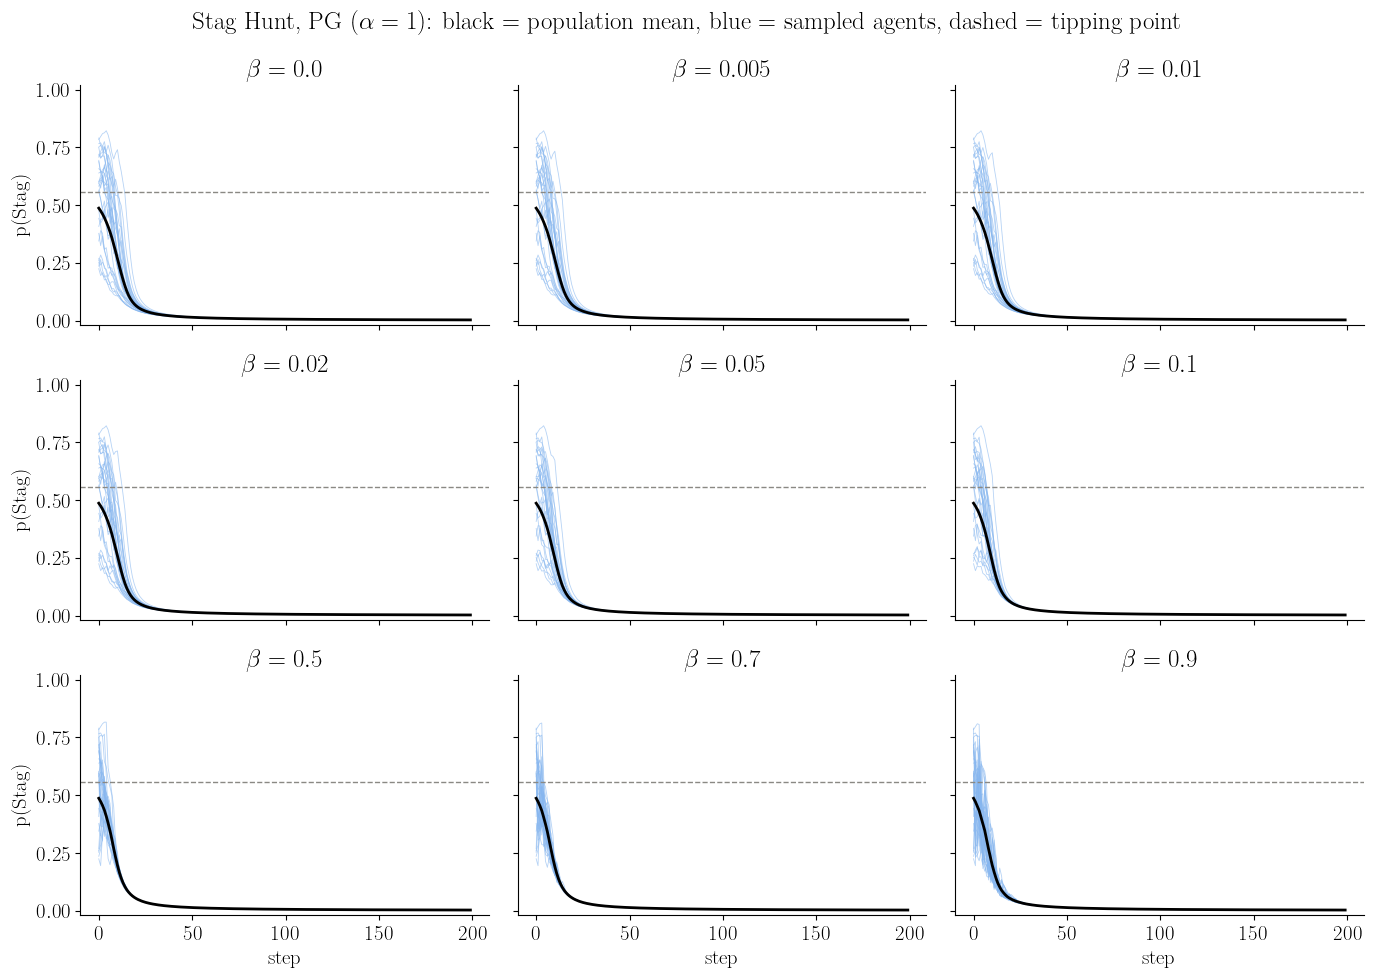

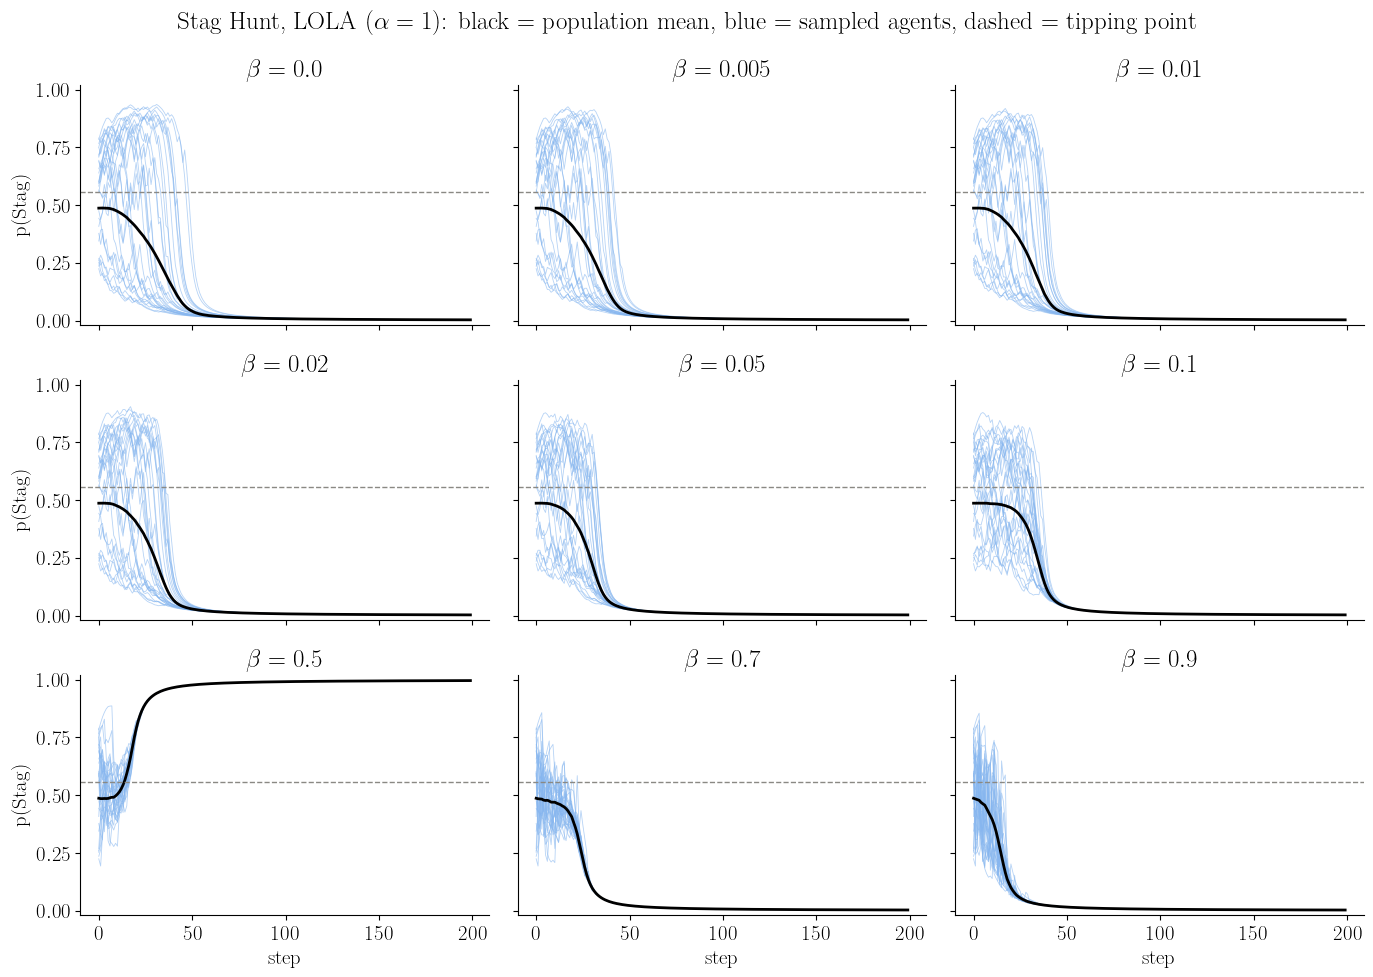

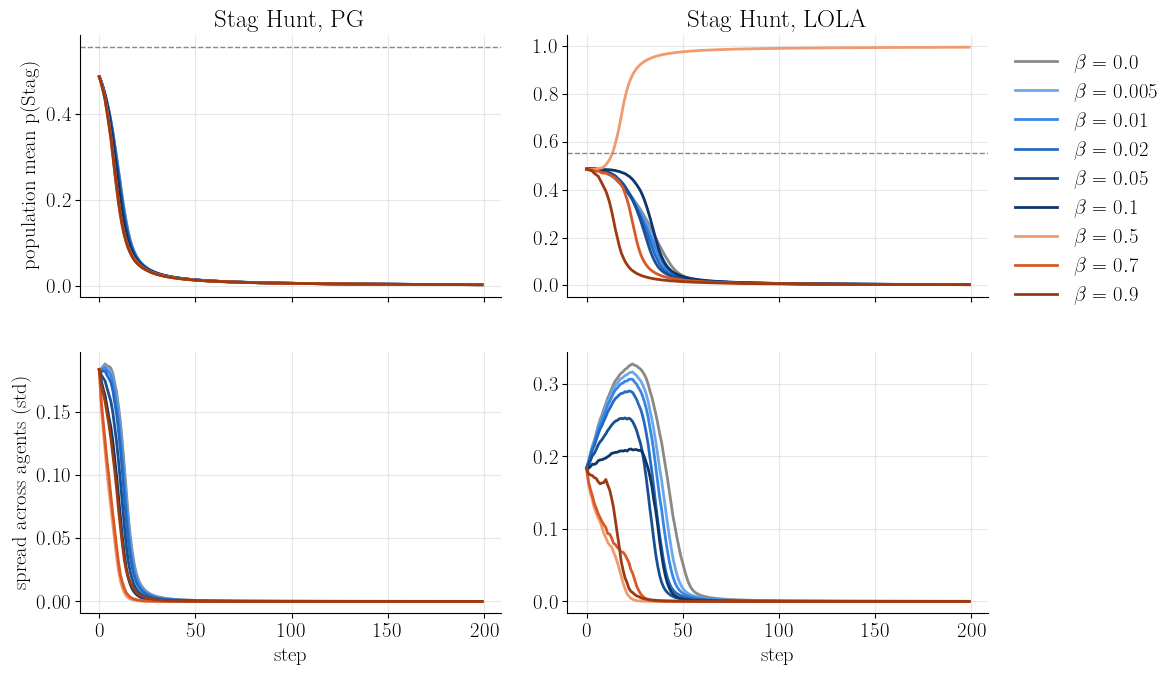

In [4]:
# hard Stag Hunt (paper's "sh1.8"): pure Nash at all-Stag and all-Hare,
# a population with p(Stag) above 1/1.8 is pulled to Stag, below it to Hare
sh_results = run_two_action_sweep("sh", steps=200)
plot_two_action_sweep(sh_results, "Stag Hunt", "Stag", 1 / 1.8, "tipping point")